# PerfectPetClub – Data Engineering and ETL Pipeline

## Project Overview

The aim of this project is to prepare customer data from multiple sources
for subscription churn analysis and prediction.

This notebook focuses on extracting, cleaning, transforming, integrating,
and validating data from the PerfectPetClub database and external datasets.

The final output is a consolidated customer-level dataset that will be
used in the PySpark machine learning pipeline.

### ETL Workflow

1. Environment setup and configuration
2. Data extraction from multiple sources
3. Database schema exploration
4. Database feature engineering
5. CRM data processing
6. Customer engagement and survey feature engineering
7. Data integration and validation
8. Exploratory data visualisation

## 1. Environment Setup and Configuration

Import the required libraries and configure the environment, storage
connections, file paths, and other settings needed to execute the ETL
pipeline.

In [1]:
import os
import re
import logging
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S"
)
logger = logging.getLogger("PerfectPetClub_ETL")

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

DATA_DIR = Path(".")
DB_PATH = DATA_DIR / "PerfectPetClub.db"
CRM_PATH = DATA_DIR / "PerfectPetClub_CRM_report.csv"
LOG_PATH = DATA_DIR / "PerfectPetClub_server_log.csv"
SURVEY_PATH = DATA_DIR / "PerfectPetClub_survey.csv"
QUESTIONS_PATH = DATA_DIR / "PerfectPetClub_survey_questions.txt"
OUTPUT_PARQUET = DATA_DIR / "customer_churn.parquet"

S3_CONFIG = {
    "endpoint_url": "http://vuh-la-specs-s3-1.herts.ac.uk:9000",
    "aws_access_key_id": "gcx63N1ce4HiITy0GQ2y",
    "aws_secret_access_key": "lK0znVWRwCmaMoqLR4LX2CESqdfSL8VGA4rN2jbV",
    "bucket": "comsci-student-s3-1",
    "key": "PerfectPetClub_survey.csv"
}

logger.info("Environment and configuration initialized.")

2026-11-15 15:31:11 | INFO     | Environment and configuration initialized.


## 2. Data Extraction from Multiple Sources

Retrieve the required datasets from their respective sources.

This stage extracts the SQLite database tables and loads the external
CRM, server log, and customer survey datasets for further processing.

In [2]:
def fetch_survey_from_s3(local_path: Path, s3_cfg: dict) -> Path:
    """Downloads the survey CSV from UH S3/MinIO block storage if not cached locally."""
    if local_path.exists():
        logger.info(f"Using cached local survey file: {local_path}")
        return local_path

    try:
        import boto3
        from botocore.config import Config
        logger.info("Connecting to UH MinIO S3 storage to download survey dataset...")
        s3_client = boto3.client(
            "s3",
            endpoint_url=s3_cfg["endpoint_url"],
            aws_access_key_id=s3_cfg["aws_access_key_id"],
            aws_secret_access_key=s3_cfg["aws_secret_access_key"],
            config=Config(connect_timeout=5, retries={"max_attempts": 2})
        )
        s3_client.download_file(s3_cfg["bucket"], s3_cfg["key"], str(local_path))
        logger.info(f"Successfully downloaded {s3_cfg['key']} from S3.")
    except Exception as exc:
        logger.error(f"S3 download failed ({exc}). Ensure UH VPN is active or file is placed locally.")
        raise FileNotFoundError(f"Could not locate or download {local_path}") from exc
    return local_path


def extract_sqlite_tables(db_path: Path) -> dict:
    """Extracts all user tables from the SQLite database into a dictionary of DataFrames."""
    if not db_path.exists():
        raise FileNotFoundError(f"SQLite database not found at {db_path}")

    tables = {}
    with sqlite3.connect(db_path) as conn:
        table_names = pd.read_sql_query(
            "SELECT name FROM sqlite_master WHERE type='table' AND name != 'sqlite_sequence';",
            conn
        )["name"].tolist()

        for tbl in table_names:
            df = pd.read_sql_query(f"SELECT * FROM {tbl};", conn)
            tables[tbl] = df
            logger.info(f"Extracted SQLite table '{tbl:<18}' -> {df.shape[0]:>6,} rows, {df.shape[1]} cols")
    return tables


def extract_all_sources() -> tuple:
    """Orchestrates extraction across SQLite, S3/local survey, CRM CSV, server log CSV, and survey metadata."""
    fetch_survey_from_s3(SURVEY_PATH, S3_CONFIG)
    db_tables = extract_sqlite_tables(DB_PATH)

    crm_df = pd.read_csv(CRM_PATH)
    logger.info(f"Extracted CRM report               -> {crm_df.shape[0]:>6,} rows, {crm_df.shape[1]} cols")

    log_df = pd.read_csv(LOG_PATH)
    logger.info(f"Extracted Server log               -> {log_df.shape[0]:>6,} rows, {log_df.shape[1]} cols")

    survey_df = pd.read_csv(SURVEY_PATH)
    logger.info(f"Extracted Survey responses         -> {survey_df.shape[0]:>6,} rows, {survey_df.shape[1]} cols")

    questions_text = QUESTIONS_PATH.read_text(encoding="utf-8") if QUESTIONS_PATH.exists() else ""
    return db_tables, crm_df, log_df, survey_df, questions_text


db_tables, crm_raw, log_raw, survey_raw, survey_questions_txt = extract_all_sources()
print("\n--- Survey Questions Metadata ---")
print(survey_questions_txt)

2026-11-12 13:28:40 | INFO     | Using cached local survey file: PerfectPetClub_survey.csv
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'payment           ' -> 23,188 rows, 4 cols
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'product_category  ' ->     26 rows, 2 cols
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'product           ' ->    194 rows, 4 cols
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'subscription_type ' ->      3 rows, 3 cols
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'subscription      ' ->    221 rows, 5 cols
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'customer          ' ->    221 rows, 9 cols
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'sale              ' -> 23,188 rows, 6 cols
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'sale_product      ' -> 59,759 rows, 4 cols
2026-11-12 13:28:40 | INFO     | Extracted SQLite table 'product_review    ' -> 10,990 rows, 5 cols
2026-11-1


--- Survey Questions Metadata ---
WebApp Popup Survey Questions 
email = customers email from logged in session.
reported_income = Q1. "What income bracket are you in?" [drop-down selector]
nps_recommend = Q2. "Would you recommend us to a friend? (no 0 - 10 yes)" [rating slider 0-10]
satisfaction_score = Q3. "Would you recommend us to a friend? (no 0 - 10 yes)" [rating slider 0-10]
online_comparison_freq = Q4. "How much time do you spend online shopping and comparing prices?" [rating slider 0-10]




## 3. Database Schema Exploration

Examine the structure of the extracted database tables, including
their columns, data types, relationships, and available records.

Understanding the database structure helps identify the relationships
required for customer-level feature engineering.

In [3]:
def document_database_schema(db_path: Path) -> pd.DataFrame:
    """Programmatically documents tables, row counts, columns, primary keys, and foreign keys."""
    schema_records = []
    with sqlite3.connect(db_path) as conn:
        tables = pd.read_sql_query(
            "SELECT name FROM sqlite_master WHERE type='table' AND name != 'sqlite_sequence';", conn
        )["name"]
        for tbl in tables:
            row_cnt = pd.read_sql_query(f"SELECT COUNT(*) AS cnt FROM {tbl};", conn)["cnt"].iloc[0]
            cols_info = pd.read_sql_query(f"PRAGMA table_info({tbl});", conn)
            fk_info = pd.read_sql_query(f"PRAGMA foreign_key_list({tbl});", conn)
            fk_map = {r["from"]: f"{r['table']}.{r['to']}" for _, r in fk_info.iterrows()}

            for _, col in cols_info.iterrows():
                schema_records.append({
                    "Table": tbl,
                    "Rows": row_cnt,
                    "Column": col["name"],
                    "Type": col["type"],
                    "NotNull": bool(col["notnull"]),
                    "PrimaryKey": bool(col["pk"]),
                    "ForeignKey": fk_map.get(col["name"], "-")
                })
    return pd.DataFrame(schema_records)


schema_doc_df = document_database_schema(DB_PATH)
display(schema_doc_df)

,Table,Rows,Column,Type,NotNull,PrimaryKey,ForeignKey
0,payment,23188,id,INTEGER,True,True,-
1,payment,23188,amount,INTEGER,True,False,-
2,payment,23188,payment_gateway,TEXT,True,False,-
3,payment,23188,transaction_reference,TEXT,True,False,-
4,product_category,26,id,INTEGER,True,True,-
5,product_category,26,name,TEXT,True,False,-
6,product,194,id,INTEGER,True,True,-
7,product,194,name,TEXT,True,False,-
8,product,194,price,INTEGER,True,False,-
9,product,194,product_category_id,INTEGER,False,False,product_category.id


## 4. Database Feature Engineering

Transform the transactional database information into meaningful
customer-level features.

This stage uses subscription, sales, payment, product, and review
information to generate features that describe customer behaviour
and purchasing patterns.

In [4]:
def engineer_database_features(tables: dict, obs_cutoff: pd.Timestamp) -> tuple:
    """Cleans and aggregates relational tables into customer-level demographic, subscription, order, delivery, and review features."""
    customer = tables["customer"].copy()
    subscription = tables["subscription"].copy()
    subscription_type = tables["subscription_type"].copy()
    sale = tables["sale"].copy()
    sale_product = tables["sale_product"].copy()
    product = tables["product"].copy()
    product_category = tables["product_category"].copy()
    payment = tables["payment"].copy()
    product_review = tables["product_review"].copy()

    # 1. Integrity check: verify payment.amount == SUM(sale_product.quantity * product.price)
    line_check = (
        sale_product.merge(product[["id", "price"]], left_on="product_id", right_on="id")
        .assign(line_total=lambda d: d["quantity"] * d["price"])
        .groupby("sale_id")["line_total"].sum()
        .reset_index()
    )
    pay_audit = sale.merge(payment, left_on="payment_id", right_on="id").merge(line_check, left_on="id_x", right_on="sale_id")
    mismatches = (pay_audit["amount"] != pay_audit["line_total"]).sum()
    assert mismatches == 0, f"Found {mismatches} payment reconciliation mismatches!"
    logger.info("Financial audit passed: 100% of 23,188 payments reconcile with line-item totals.")

    # 2. Customer + Subscription + Tier join (dropping sensitive password_hash)
    cust_sub = (
        customer.drop(columns=["password_hash"])
        .merge(subscription, left_on="subscription_id", right_on="id", suffixes=("", "_sub"))
        .merge(subscription_type, left_on="subscription_type_id", right_on="id", suffixes=("", "_type"))
        .rename(columns={"id": "customer_id", "name_type": "subscription_tier"})
    )
    cust_sub["churn"] = (cust_sub["auto_renew"] == 0).astype(int)
    cust_sub["start_dt"] = pd.to_datetime(cust_sub["start_date"])
    cust_sub["end_dt"] = pd.to_datetime(cust_sub["end_date"])
    cust_sub["active_end_dt"] = cust_sub["end_dt"].clip(upper=obs_cutoff)
    cust_sub["active_tenure_days"] = ((cust_sub["active_end_dt"] - cust_sub["start_dt"]).dt.total_seconds() / 86400.0).clip(lower=1.0)
    cust_sub["active_tenure_months"] = cust_sub["active_tenure_days"] / 30.0

    tier_fee_map = {"Premium": 11.99, "Basic": 7.99, "SuperSaver": 2.99}
    cust_sub["subscription_monthly_fee_gbp"] = cust_sub["subscription_tier"].map(tier_fee_map)

    # 3. Orders, Payments & Delivery SLA Metrics
    sale["order_dt"] = pd.to_datetime(sale["order_date"])
    sale["expected_dt"] = pd.to_datetime(sale["expected_date"])
    sale["delivered_dt"] = pd.to_datetime(sale["delivered_date"])
    sale["is_subscription_renewal"] = sale["expected_dt"].isna().astype(int)
    sale["delivery_delay_hours"] = (sale["delivered_dt"] - sale["expected_dt"]).dt.total_seconds() / 3600.0
    sale["is_late_delivery"] = np.where(
        sale["delivered_dt"].notna(),
        (sale["delivered_dt"] > sale["expected_dt"]).astype(float),
        np.nan
    )

    sale_pay = sale.merge(payment, left_on="payment_id", right_on="id", suffixes=("", "_pay"))
    sale_pay["amount_gbp"] = sale_pay["amount"] / 100.0

    cust_sales = sale_pay.groupby("customer_id").agg(
        total_orders=("id", "count"),
        physical_orders=("is_subscription_renewal", lambda x: (x == 0).sum()),
        subscription_renewals=("is_subscription_renewal", "sum"),
        total_spend_gbp=("amount_gbp", "sum"),
        avg_order_value_gbp=("amount_gbp", "mean"),
        std_order_value_gbp=("amount_gbp", "std"),
        late_deliveries=("is_late_delivery", "sum"),
        late_delivery_rate=("is_late_delivery", "mean"),
        avg_delivery_delay_hours=("delivery_delay_hours", "mean"),
        max_delivery_delay_hours=("delivery_delay_hours", "max")
    ).reset_index()

    gw_share = (
        pd.crosstab(sale_pay["customer_id"], sale_pay["payment_gateway"], normalize="index")
        .add_prefix("gw_share_")
        .reset_index()
    )

    # 4. Basket Diversity & Pet Segment Inference
    sp_enriched = (
        sale_product.merge(product, left_on="product_id", right_on="id", suffixes=("", "_prod"))
        .merge(product_category, left_on="product_category_id", right_on="id", how="left", suffixes=("", "_cat"))
        .merge(sale[["id", "customer_id"]], left_on="sale_id", right_on="id", suffixes=("", "_sale"))
    )
    sp_enriched["category_name"] = sp_enriched["name_cat"].fillna("Subscription Renewal")
    sp_enriched["is_physical_item"] = sp_enriched["product_category_id"].notna().astype(int)

    def infer_pet_segment(cat: str) -> str:
        if "Dog" in cat:
            return "Dog"
        if "Cat" in cat:
            return "Cat"
        if "Bird" in cat or "Aquatic" in cat:
            return "Bird_Aquatic"
        if "Small Animal" in cat:
            return "Small_Animal"
        return "General_Pet"

    sp_enriched["pet_segment"] = sp_enriched["category_name"].apply(infer_pet_segment)

    phys_items = sp_enriched[sp_enriched["is_physical_item"] == 1]
    cust_basket = phys_items.groupby("customer_id").agg(
        total_physical_units=("quantity", "sum"),
        unique_products_bought=("product_id", "nunique"),
        unique_categories_bought=("category_name", "nunique")
    ).reset_index()

    pet_pivot = (
        phys_items[phys_items["pet_segment"] != "General_Pet"]
        .groupby(["customer_id", "pet_segment"])["quantity"]
        .sum()
        .unstack(fill_value=0)
    )
    pet_pivot["primary_pet_segment"] = pet_pivot.idxmax(axis=1)
    cust_pet = pet_pivot[["primary_pet_segment"]].reset_index()

    # 5. Product Reviews Aggregation
    cust_reviews = product_review.groupby("customer_id").agg(
        review_count=("id", "count"),
        avg_star_rating=("star_rating", "mean"),
        min_star_rating=("star_rating", "min"),
        low_rating_count=("star_rating", lambda x: (x <= 2).sum()),
        low_rating_ratio=("star_rating", lambda x: (x <= 2).mean())
    ).reset_index()

    db_features = (
        cust_sub[[
            "customer_id", "name", "email", "county", "postcode",
            "subscription_tier", "delivery_service", "subscription_monthly_fee_gbp",
            "active_end_dt", "active_tenure_days", "active_tenure_months", "churn"
        ]]
        .merge(cust_sales, on="customer_id", how="left")
        .merge(gw_share, on="customer_id", how="left")
        .merge(cust_basket, on="customer_id", how="left")
        .merge(cust_pet, on="customer_id", how="left")
        .merge(cust_reviews, on="customer_id", how="left")
    )

    logger.info(f"Part 1 complete: Engineered {db_features.shape[1]} database features for {len(db_features)} customers.")
    return db_features, sale_pay


OBS_CUTOFF = pd.to_datetime("2026-11-11 00:00:00")
db_cust_df, sale_pay_clean = engineer_database_features(db_tables, OBS_CUTOFF)
display(db_cust_df.head(3))

2026-11-12 13:29:11 | INFO     | Financial audit passed: 100% of 23,188 payments reconcile with line-item totals.
2026-11-12 13:29:11 | INFO     | Part 1 complete: Engineered 34 database features for 221 customers.


,customer_id,name,email,county,postcode,subscription_tier,delivery_service,subscription_monthly_fee_gbp,active_end_dt,active_tenure_days,...,gw_share_paypool,total_physical_units,unique_products_bought,unique_categories_bought,primary_pet_segment,review_count,avg_star_rating,min_star_rating,low_rating_count,low_rating_ratio
0,1,Anahit Sargsyan,Sargsyan701@somemail.co.uk,Berkshire,SL6 1CD,SuperSaver,Economy72,2.99,2026-01-31,30.0,...,1.0,45.0,33.0,11.0,Cat,10.0,2.400000,1.0,6.0,0.600000
1,2,Leyla Mammadova,Mammadova282@example.com,Oxfordshire,OX7 5GH,SuperSaver,Economy72,2.99,2026-11-11,314.0,...,0.0,737.0,63.0,17.0,Cat,113.0,3.176991,1.0,41.0,0.362832
2,3,Sana Shah,Sana858@notrealemail.com,Worcestershire,DY10 2JK,Premium,SignedFor24,11.99,2026-11-11,314.0,...,0.0,813.0,63.0,17.0,Cat,134.0,3.082090,1.0,49.0,0.365672


## 5. CRM Data Cleaning and Feature Engineering

Process the CRM records to identify useful customer interaction
information.

Generate customer-level features from complaint and query records
to represent customer service interactions.

In [5]:
def engineer_crm_features(crm_df: pd.DataFrame, valid_customer_ids: pd.Series) -> tuple:
    """Cleans CRM contact records and aggregates customer-level service & complaint indicators."""
    crm = crm_df.copy()

    crm = crm.rename(columns={"recieved_datatime": "received_datetime"})
    crm["received_dt"] = pd.to_datetime(crm["received_datetime"])
    crm["platform_clean"] = crm["platform"].astype(str).str.replace(r"[\[\]']", "", regex=True).str.strip()
    crm["type_clean"] = crm["type"].astype(str).str.strip().str.lower()

    assert set(crm["platform_clean"].unique()).issubset({"e-mail", "telephone", "live-chat"}), "Unexpected CRM platform!"
    assert set(crm["type_clean"].unique()).issubset({"complaint", "query"}), "Unexpected CRM ticket type!"
    assert crm["customer_id"].isin(valid_customer_ids).all(), "Orphan customer_id found in CRM report!"

    crm["is_complaint"] = (crm["type_clean"] == "complaint").astype(int)
    crm["is_query"] = (crm["type_clean"] == "query").astype(int)

    cust_crm = crm.groupby("customer_id").agg(
        crm_total_contacts=("customer_id", "count"),
        crm_complaints=("is_complaint", "sum"),
        crm_queries=("is_query", "sum"),
        crm_email_count=("platform_clean", lambda x: (x == "e-mail").sum()),
        crm_phone_count=("platform_clean", lambda x: (x == "telephone").sum()),
        crm_chat_count=("platform_clean", lambda x: (x == "live-chat").sum())
    ).reset_index()

    cust_crm["crm_complaint_ratio"] = np.where(
        cust_crm["crm_total_contacts"] > 0,
        cust_crm["crm_complaints"] / cust_crm["crm_total_contacts"],
        0.0
    )
    cust_crm["crm_high_touch_channel_share"] = np.where(
        cust_crm["crm_total_contacts"] > 0,
        (cust_crm["crm_phone_count"] + cust_crm["crm_chat_count"]) / cust_crm["crm_total_contacts"],
        0.0
    )

    logger.info(f"Part 2 complete: Cleaned {len(crm):,} CRM tickets across {len(cust_crm)} active support users.")
    return cust_crm, crm


crm_cust_df, crm_clean = engineer_crm_features(crm_raw, db_cust_df["customer_id"])
display(crm_cust_df.head(3))

2026-11-12 13:29:35 | INFO     | Part 2 complete: Cleaned 7,585 CRM tickets across 200 active support users.


,customer_id,crm_total_contacts,crm_complaints,crm_queries,crm_email_count,crm_phone_count,crm_chat_count,crm_complaint_ratio,crm_high_touch_channel_share
0,1,3,2,1,1,2,0,0.666667,0.666667
1,2,45,21,24,28,10,7,0.466667,0.377778
2,3,167,90,77,106,37,24,0.538922,0.365269


## 6. Customer Engagement and Survey Feature Engineering

Process server log and survey information to generate additional
customer-level features.

The engagement features describe customer activity, while survey
features capture reported satisfaction, recommendation, income,
and online comparison behaviour.

In [6]:
def engineer_engagement_and_survey_features(
    log_df: pd.DataFrame,
    survey_df: pd.DataFrame,
    valid_emails: pd.Series
) -> tuple:
    """Parses server session logs and customer survey data into engagement and satisfaction features."""
    log = log_df.copy()
    assert log["session_id"].is_unique, "Duplicate session_id detected in server logs!"
    assert log["login"].isin(valid_emails).all(), "Unrecognized login email in server logs!"

    log["login_dt"] = pd.to_datetime(log["datetime"])
    log["device_type"] = log["user_agent"].str.extract(r"\(([^;]+);")[0].fillna("Unknown")
    log["login_hour"] = log["login_dt"].dt.hour
    log["is_weekend"] = log["login_dt"].dt.dayofweek.isin([5, 6]).astype(int)

    cust_log = log.groupby("login").agg(
        total_logins=("session_id", "count"),
        unique_ips=("ip", "nunique"),
        weekend_login_ratio=("is_weekend", "mean"),
        evening_login_ratio=("login_hour", lambda x: ((x >= 17) & (x <= 22)).mean())
    ).reset_index().rename(columns={"login": "email"})

    dev_share = (
        pd.crosstab(log["login"], log["device_type"], normalize="index")
        .rename(columns={
            "Desktop/Laptop": "device_share_desktop",
            "Mobile": "device_share_mobile",
            "Tablet": "device_share_tablet"
        })
        .reset_index()
        .rename(columns={"login": "email"})
    )
    cust_engagement = cust_log.merge(dev_share, on="email", how="left")

    surv = survey_df.copy()
    assert surv["email"].is_unique, "Duplicate survey submissions per customer!"
    assert surv["email"].isin(valid_emails).all(), "Unrecognized email in survey responses!"

    def parse_income_midpoint(val: str) -> float:
        cleaned = str(val).replace("k", "").replace("+", "").strip()
        low, high = cleaned.split("-")
        return (float(low) + float(high)) / 2.0

    surv["income_midpoint_k"] = surv["reported_income"].apply(parse_income_midpoint)
    surv["composite_sentiment_score"] = (surv["nps_recommend"] + surv["satisfaction_score"]) / 2.0
    surv["nps_satisfaction_gap"] = surv["nps_recommend"] - surv["satisfaction_score"]
    surv["is_nps_detractor"] = (surv["nps_recommend"] <= 6).astype(int)
    surv["is_nps_promoter"] = (surv["nps_recommend"] >= 9).astype(int)
    surv["price_sensitivity_risk"] = (
        (surv["online_comparison_freq"] >= 7) & (surv["composite_sentiment_score"] <= 5)
    ).astype(int)

    cust_survey = surv.drop(columns=["reported_income"])
    logger.info(f"Part 3 complete: Engineered engagement ({cust_engagement.shape[1]} cols) & survey ({cust_survey.shape[1]} cols) features.")
    return cust_engagement, cust_survey, log


def engineer_velocity_features(
    base_df: pd.DataFrame,
    sale_pay: pd.DataFrame,
    log_clean: pd.DataFrame,
    crm_clean: pd.DataFrame
) -> pd.DataFrame:
    """Computes 30-day pre-cutoff behavioral velocity (last 30 active days vs. prior 30 days)."""
    rows = []
    for _, r in base_df.iterrows():
        cid = r["customer_id"]
        email = r["email"]
        e_dt = r["active_end_dt"]
        w30 = e_dt - pd.Timedelta(days=30)
        w60 = e_dt - pd.Timedelta(days=60)

        s_c = sale_pay[(sale_pay["customer_id"] == cid) & (sale_pay["order_dt"] <= e_dt)]
        l_c = log_clean[(log_clean["login"] == email) & (log_clean["login_dt"] <= e_dt)]
        m_c = crm_clean[(crm_clean["customer_id"] == cid) & (crm_clean["received_dt"] <= e_dt)]

        ord_last30 = int((s_c["order_dt"] >= w30).sum())
        ord_prev30 = int(((s_c["order_dt"] >= w60) & (s_c["order_dt"] < w30)).sum())

        log_last30 = int((l_c["login_dt"] >= w30).sum())
        log_prev30 = int(((l_c["login_dt"] >= w60) & (l_c["login_dt"] < w30)).sum())

        cmp_last30 = int(((m_c["received_dt"] >= w30) & (m_c["is_complaint"] == 1)).sum())
        cmp_prev30 = int(((m_c["received_dt"] >= w60) & (m_c["received_dt"] < w30) & (m_c["is_complaint"] == 1)).sum())

        rows.append({
            "customer_id": cid,
            "orders_last_30d": ord_last30,
            "orders_prev_30d": ord_prev30,
            "order_velocity_change": ord_last30 - ord_prev30,
            "order_velocity_ratio": (ord_last30 + 1.0) / (ord_prev30 + 1.0),
            "logins_last_30d": log_last30,
            "logins_prev_30d": log_prev30,
            "login_velocity_change": log_last30 - log_prev30,
            "login_velocity_ratio": (log_last30 + 1.0) / (log_prev30 + 1.0),
            "complaints_last_30d": cmp_last30,
            "complaints_prev_30d": cmp_prev30,
            "complaint_velocity_change": cmp_last30 - cmp_prev30
        })
    return pd.DataFrame(rows)


eng_cust_df, surv_cust_df, log_clean = engineer_engagement_and_survey_features(
    log_raw, survey_raw, db_cust_df["email"]
)
vel_cust_df = engineer_velocity_features(db_cust_df, sale_pay_clean, log_clean, crm_clean)
display(vel_cust_df.head(3))

2026-11-12 13:29:44 | INFO     | Part 3 complete: Engineered engagement (8 cols) & survey (10 cols) features.


,customer_id,orders_last_30d,orders_prev_30d,order_velocity_change,order_velocity_ratio,logins_last_30d,logins_prev_30d,login_velocity_change,login_velocity_ratio,complaints_last_30d,complaints_prev_30d,complaint_velocity_change
0,1,20,0,20,21.000000,48,0,48,49.000000,2,0,2
1,2,17,10,7,1.636364,58,67,-9,0.867647,2,1,1
2,3,27,14,13,1.866667,43,42,1,1.023256,7,4,3


## 7. Data Integration, Validation and Export

Combine the engineered database, CRM, engagement, and survey features
into a consolidated customer-level dataset.

Validate the integrated dataset by checking its structure, customer
records, missing values, and consistency.

Finally, export the prepared dataset in Parquet format for use in
the machine learning notebook.

In [7]:
def integrate_validate_and_load(
    db_df: pd.DataFrame,
    crm_df: pd.DataFrame,
    eng_df: pd.DataFrame,
    surv_df: pd.DataFrame,
    vel_df: pd.DataFrame,
    output_path: Path
) -> pd.DataFrame:
    """Integrates all feature sets, computes normalized behavioral ratios, runs QA assertions, and writes Parquet."""
    master = (
        db_df
        .merge(crm_df, on="customer_id", how="left")
        .merge(eng_df, on="email", how="left")
        .merge(surv_df, on="email", how="left")
        .merge(vel_df, on="customer_id", how="left")
    )

    zero_cols = [
        "crm_total_contacts", "crm_complaints", "crm_queries",
        "crm_email_count", "crm_phone_count", "crm_chat_count",
        "crm_complaint_ratio", "crm_high_touch_channel_share",
        "review_count", "low_rating_count", "low_rating_ratio",
        "late_deliveries", "late_delivery_rate",
        "avg_delivery_delay_hours", "max_delivery_delay_hours",
        "total_physical_units", "unique_products_bought", "unique_categories_bought",
        "std_order_value_gbp"
    ]
    for col in zero_cols:
        master[col] = master[col].fillna(0.0)

    master["primary_pet_segment"] = master["primary_pet_segment"].fillna("General_Pet")
    master["avg_star_rating"] = master["avg_star_rating"].fillna(master["avg_star_rating"].median())
    master["min_star_rating"] = master["min_star_rating"].fillna(master["min_star_rating"].median())

    tenure_m = master["active_tenure_months"]
    master["orders_per_month"] = master["total_orders"] / tenure_m
    master["physical_orders_per_month"] = master["physical_orders"] / tenure_m
    master["spend_per_month_gbp"] = master["total_spend_gbp"] / tenure_m
    master["logins_per_month"] = master["total_logins"] / tenure_m
    master["crm_contacts_per_month"] = master["crm_total_contacts"] / tenure_m
    master["complaints_per_month"] = master["crm_complaints"] / tenure_m
    master["orders_per_login"] = master["total_orders"] / master["total_logins"].clip(lower=1)
    master["complaints_per_order"] = master["crm_complaints"] / master["total_orders"].clip(lower=1)

    master = master.drop(columns=["active_end_dt"])

    assert len(master) == 221, f"Expected 221 customers, got {len(master)}"
    assert master["customer_id"].is_unique, "Primary key customer_id is not unique!"
    assert master["email"].is_unique, "Email key is not unique!"
    null_total = int(master.isnull().sum().sum())
    assert null_total == 0, f"Data quality check failed: {null_total} null values remain!"
    assert set(master["churn"].unique()) == {0, 1}, "Target variable 'churn' must be binary {0, 1}!"

    master.to_parquet(output_path, index=False)
    file_kb = output_path.stat().st_size / 1024.0
    logger.info(f"QA assertions passed! Saved '{output_path}' ({master.shape[0]} rows x {master.shape[1]} cols, {file_kb:.1f} KB).")
    return master


customer_churn_df = integrate_validate_and_load(
    db_cust_df, crm_cust_df, eng_cust_df, surv_cust_df, vel_cust_df, OUTPUT_PARQUET
)
display(customer_churn_df.head(5))

2026-11-12 13:29:57 | INFO     | QA assertions passed! Saved 'customer_churn.parquet' (221 rows x 76 cols, 105.9 KB).


,customer_id,name,email,county,postcode,subscription_tier,delivery_service,subscription_monthly_fee_gbp,active_tenure_days,active_tenure_months,...,complaints_prev_30d,complaint_velocity_change,orders_per_month,physical_orders_per_month,spend_per_month_gbp,logins_per_month,crm_contacts_per_month,complaints_per_month,orders_per_login,complaints_per_order
0,1,Anahit Sargsyan,Sargsyan701@somemail.co.uk,Berkshire,SL6 1CD,SuperSaver,Economy72,2.99,30.0,1.000000,...,0,2,20.000000,19.000000,744.550000,48.000000,3.000000,2.000000,0.416667,0.100000
1,2,Leyla Mammadova,Mammadova282@example.com,Oxfordshire,OX7 5GH,SuperSaver,Economy72,2.99,314.0,10.466667,...,1,1,24.171975,23.121019,990.727070,103.662420,4.299363,2.006369,0.233180,0.083004
2,3,Sana Shah,Sana858@notrealemail.com,Worcestershire,DY10 2JK,Premium,SignedFor24,11.99,314.0,10.466667,...,4,3,29.044586,27.993631,1227.412739,59.617834,15.955414,8.598726,0.487179,0.296053
3,4,Omar Farooq,Omar.Farooq4@example.com,Kent,TN9 1LM,Premium,SignedFor24,11.99,314.0,10.466667,...,10,-2,100.796178,99.745223,9150.481529,147.133758,26.847134,12.611465,0.685065,0.125118
4,5,Alejandro Blanco,Alejandro357@somemail.co.uk,Hertfordshire,WD7 8PQ,SuperSaver,Economy72,2.99,120.0,4.000000,...,0,0,11.000000,10.000000,449.345000,97.000000,1.250000,0.250000,0.113402,0.022727


## 8. Exploratory Data Visualisation

Use visualisations to understand the distribution of customer
characteristics and the patterns present in the engineered dataset.

These visualisations provide an initial understanding of the data
before proceeding to machine learning.

/var/folders/rn/wkxv6s393lncmzytf2r9dvqm0000gn/T/ipykernel_3245/2715542170.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tier_churn, x="subscription_tier", y="mean", ax=axes[0, 0], palette="viridis")
2026-11-12 13:30:05 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
/var/folders/rn/wkxv6s393lncmzytf2r9dvqm0000gn/T/ipykernel_3245/2715542170.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=customer_churn_df, x="churn", y="login_velocity_change", ax=axes[0, 1], palette="Set2")
2026-11-12 13:30:05 | INFO     | Using cate

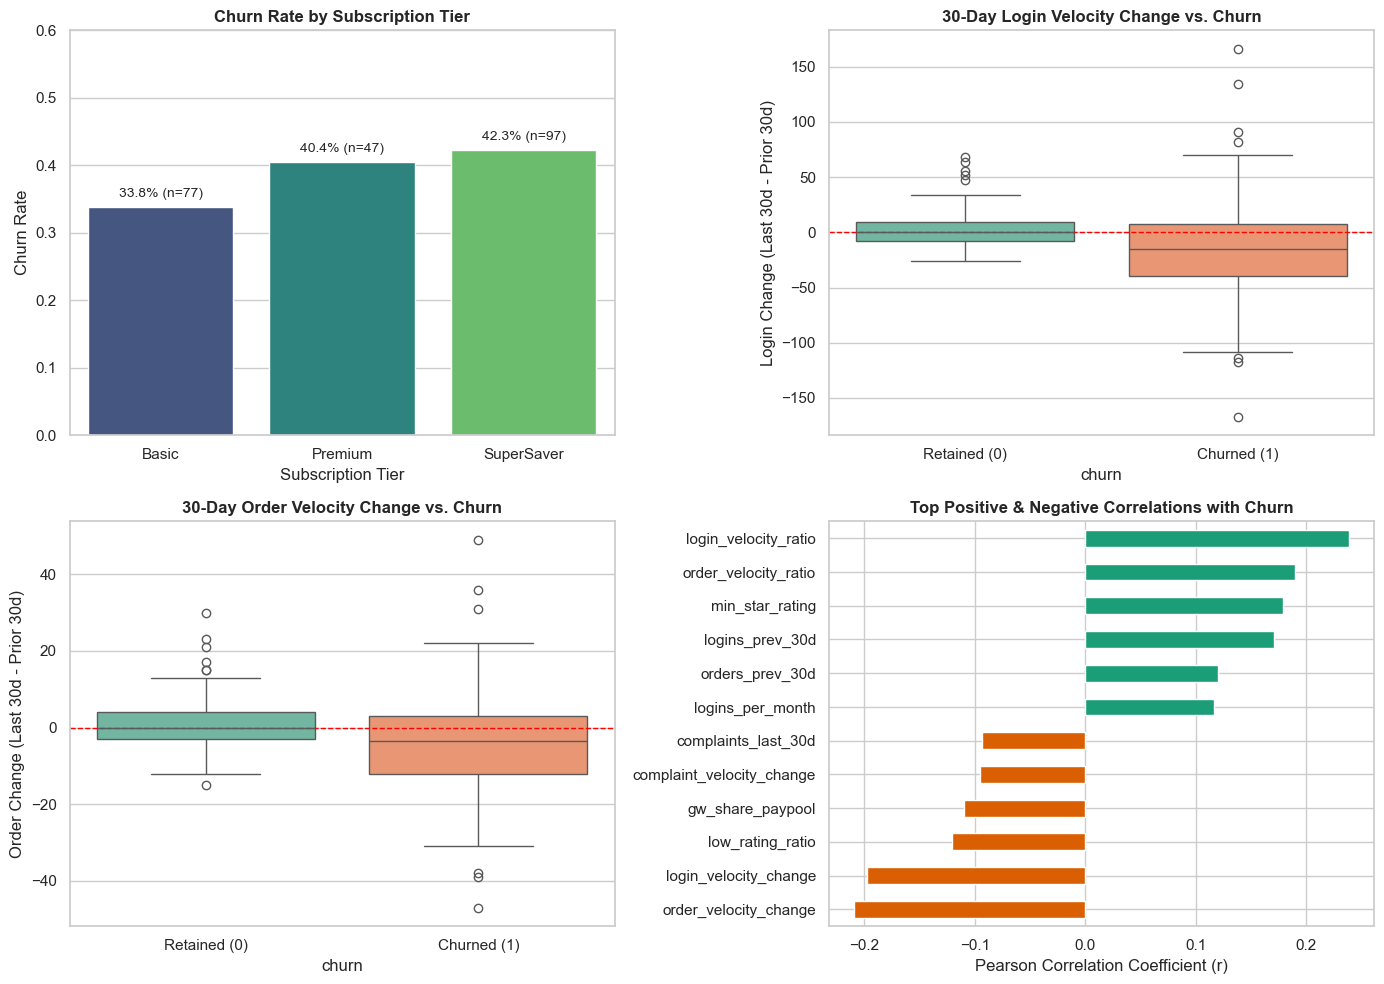

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

tier_churn = customer_churn_df.groupby("subscription_tier")["churn"].agg(["count", "mean"]).reset_index()
sns.barplot(data=tier_churn, x="subscription_tier", y="mean", ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title("Churn Rate by Subscription Tier", fontweight="bold")
axes[0, 0].set_ylabel("Churn Rate")
axes[0, 0].set_xlabel("Subscription Tier")
for idx, row in tier_churn.iterrows():
    axes[0, 0].text(idx, row["mean"] + 0.015, f"{row['mean']*100:.1f}% (n={int(row['count'])})", ha="center", fontsize=10)
axes[0, 0].set_ylim(0, 0.6)

sns.boxplot(data=customer_churn_df, x="churn", y="login_velocity_change", ax=axes[0, 1], palette="Set2")
axes[0, 1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0, 1].set_title("30-Day Login Velocity Change vs. Churn", fontweight="bold")
axes[0, 1].set_xticklabels(["Retained (0)", "Churned (1)"])
axes[0, 1].set_ylabel("Login Change (Last 30d - Prior 30d)")

sns.boxplot(data=customer_churn_df, x="churn", y="order_velocity_change", ax=axes[1, 0], palette="Set2")
axes[1, 0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1, 0].set_title("30-Day Order Velocity Change vs. Churn", fontweight="bold")
axes[1, 0].set_xticklabels(["Retained (0)", "Churned (1)"])
axes[1, 0].set_ylabel("Order Change (Last 30d - Prior 30d)")

exclude_meta = {
    "customer_id", "active_tenure_days", "active_tenure_months", "total_orders",
    "physical_orders", "subscription_renewals", "total_spend_gbp", "total_physical_units",
    "review_count", "low_rating_count", "late_deliveries", "crm_total_contacts",
    "crm_complaints", "crm_queries", "crm_email_count", "crm_phone_count",
    "crm_chat_count", "total_logins", "unique_ips"
}
num_features = [c for c in customer_churn_df.select_dtypes(include=[np.number]).columns if c not in exclude_meta]
corrs = customer_churn_df[num_features].corr()["churn"].drop("churn").sort_values()
top_corrs = pd.concat([corrs.head(6), corrs.tail(6)])
top_corrs.plot(kind="barh", ax=axes[1, 1], color=["#d95f02" if v < 0 else "#1b9e77" for v in top_corrs])
axes[1, 1].set_title("Top Positive & Negative Correlations with Churn", fontweight="bold")
axes[1, 1].set_xlabel("Pearson Correlation Coefficient (r)")

plt.tight_layout()
plt.show()

## 9. ETL Pipeline Summary

The ETL process prepares a consolidated customer-level dataset by
integrating information from the database, CRM records, server logs,
and customer surveys.

The resulting dataset is exported in Parquet format and is ready
for further preparation and analysis in the PySpark machine learning
pipeline.